# 01 · Concepts with synthetic data

Before touching the real catalogue, this notebook illustrates the two ideas
the whole project is built on, using simulated data:

1. **Thresholding a marked point process.** A burst catalogue is a list of
   events, each with a time and a *mark* (its peak flux). Keeping only the
   events above a threshold turns it into a plain sequence of event times,
   whose waiting times we can study.
2. **Autocorrelation as a test of independence.** In a homogeneous Poisson
   process the waiting times are independent and exponentially distributed.
   Any memory in the process shows up as autocorrelation between
   consecutive waiting times.

In [1]:
import sys
from pathlib import Path

# Make the `srb` package (repository root) importable from this notebook.
sys.path.insert(0, str(Path.cwd().parent))

import matplotlib.pyplot as plt
import numpy as np

from srb.diagnostics import acf_confidence_bound, autocorrelation
from srb.plotting import plot_acf

## 1. Thresholding a marked point process

We simulate 500 events: the times come from a Poisson process (exponential
gaps with mean 2) and the magnitudes are exponential with mean 15. Two
thresholds select two nested subsets of events.

In [2]:
rng = np.random.default_rng(42)
N_EVENTS = 500
THRESHOLD_1 = 30.0
THRESHOLD_2 = 50.0

times = np.cumsum(rng.exponential(scale=2.0, size=N_EVENTS))
magnitudes = rng.exponential(scale=15.0, size=N_EVENTS)

times_t1 = times[magnitudes >= THRESHOLD_1]
times_t2 = times[magnitudes >= THRESHOLD_2]

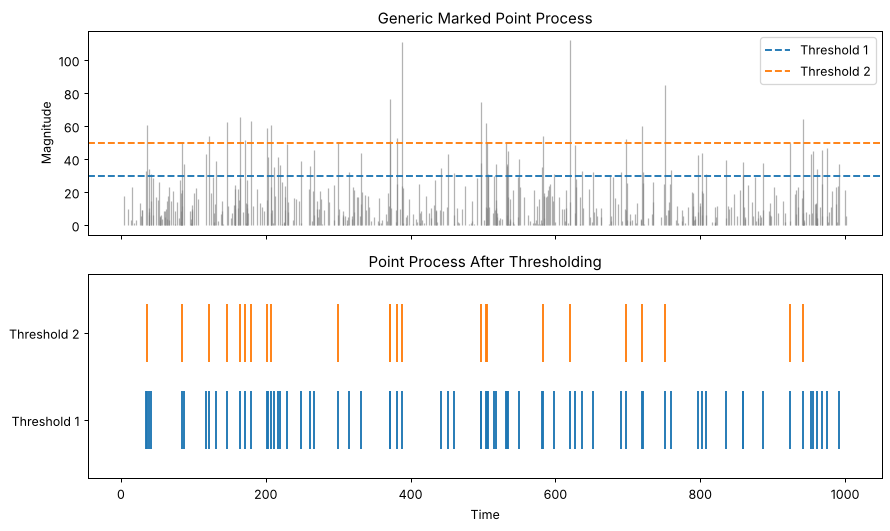

In [3]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 6), sharex=True)

# Top: every event with its magnitude, and the two thresholds.
ax1.vlines(times, ymin=0, ymax=magnitudes, color="gray", linewidth=1, alpha=0.6)
ax1.axhline(THRESHOLD_1, color="tab:blue", linestyle="--", linewidth=1.5, label="Threshold 1")
ax1.axhline(THRESHOLD_2, color="tab:orange", linestyle="--", linewidth=1.5, label="Threshold 2")
ax1.set_ylabel("Magnitude")
ax1.set_title("Generic Marked Point Process")
ax1.legend(loc="upper right")

# Bottom: the point processes that remain after each threshold.
ax2.vlines(times_t1, ymin=0.5, ymax=1.5, color="tab:blue", linewidth=1.5)
ax2.vlines(times_t2, ymin=2.0, ymax=3.0, color="tab:orange", linewidth=1.5)
ax2.set_xlabel("Time")
ax2.set_title("Point Process After Thresholding")
ax2.set_yticks([1, 2.5])
ax2.set_yticklabels(["Threshold 1", "Threshold 2"])
ax2.set_ylim(0, 3.5)

fig.tight_layout()
plt.show()

## 2. Autocorrelation: Poisson vs. non-Poisson

Two synthetic sequences of 800 waiting times:

* **Poisson**: independent exponential waiting times (rate 0.1).
* **Non-Poisson**: gamma waiting times whose mean oscillates by 20% with a
  period of 30 events, a weak periodicity.

For an independent sequence about 95% of the ACF values should fall inside
the dashed band $$\pm\frac{1.96}{\sqrt{n}}.$$

In [4]:
rng = np.random.default_rng(1)
N = 800
MAX_LAG = 60

# Homogeneous Poisson process: i.i.d. exponential waiting times.
rate = 0.1
x_poisson = rng.exponential(scale=1 / rate, size=N)

# Weakly periodic process: the mean waiting time oscillates around 10.
k = np.arange(N)
period = 30
mean_wait = 10 * (1 + 0.20 * np.sin(2 * np.pi * k / period))
x_periodic = rng.gamma(shape=4, scale=mean_wait / 4)

Homogeneous Poisson process: 2 significant lags out of 60
Non-Poisson process: 11 significant lags out of 60


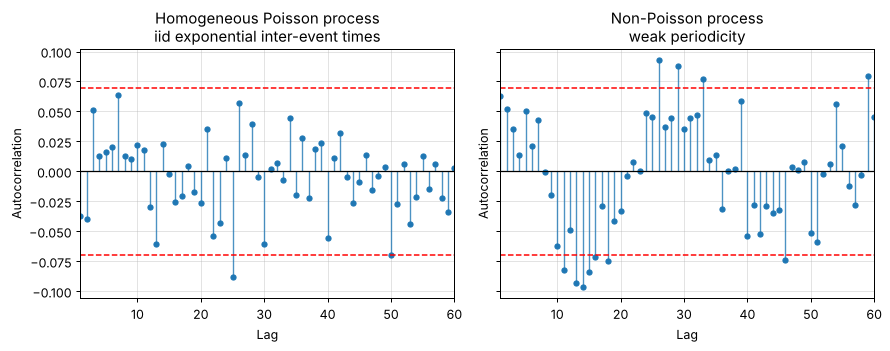

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharey=True)
bound = acf_confidence_bound(N)

for ax, x, title in [
    (axes[0], x_poisson, "Homogeneous Poisson process\niid exponential inter-event times"),
    (axes[1], x_periodic, "Non-Poisson process\nweak periodicity"),
]:
    lags, acf = autocorrelation(x, MAX_LAG)
    plot_acf(ax, lags, acf, bound, title=title)
    n_outside = np.sum(np.abs(acf) > bound)
    print(f"{title.splitlines()[0]}: {n_outside} significant lags out of {MAX_LAG}")

fig.tight_layout()
plt.show()